In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error

In [2]:
df = pd.read_csv(r"pakistan_tech_jobs_final.csv")
df.drop('job_description', inplace=True, axis=1)
df['education'] = df['education'].fillna(df['education'].mode()[0])
df['job_title'] = df['job_title'].fillna(df['job_title'].mode()[0])
df.head()

,job_id,job_title,company,required_skills,city,province,experience_min,experience_max,education,employment_type,work_mode,salary_min,salary_max,posted_date,job_category,source_website
0,1001,Senior Full-Stack & AI Engineer,Jack Mitchel,"Python, JavaScript, TypeScript, Node.js, React...",Karachi,Sindh,5.0,8.0,Bachelor's,Full-time,Remote,560000.0,840000.0,2026-10-30,Data Science / AI / ML,Bano Qabil Jobs
1,1002,"Front end developer, UI/UX Designing",Sharp Mind,"HTML, CSS, Java, UI/UX Design",Lahore,Punjab,2.0,5.0,Bachelor's,Full-time,On-site,80000.0,110000.0,2026-10-30,Web Development,Bano Qabil Jobs
2,1003,MACHINE LEARNING ENGINNER,MUHAMMAD AFNAN,"Core ML Expertise, Solid Programming (Python, ...",Lahore,Punjab,2.0,5.0,Bachelor's,Full-time,On-site,60000.0,100000.0,2026-10-30,Data Science / AI / ML,Bano Qabil Jobs
3,1004,Frontend Developer (React + Next.js),VertexInvo,"React, Next.js",Karachi,Sindh,2.0,5.0,Bachelor's,Full-time,On-site,50000.0,60000.0,2026-10-30,Web Development,Bano Qabil Jobs
4,1005,Mobile App Developer (Flutter),Mohsin Shiekh,"Python, JavaScript, SQL, Git",Karachi,Sindh,0.0,2.0,Bachelor's,Full-time,Remote,40000.0,59998.0,2026-10-30,Mobile Development,Bano Qabil Jobs


In [3]:
cols_for_sal = ['experience_min', 'city', 'job_category', 'work_mode', 'education', 'experience_max', 'salary_min', 'salary_max', 'required_skills']
reg_df = df[cols_for_sal].copy()
reg_df.head()


,experience_min,city,job_category,work_mode,education,experience_max,salary_min,salary_max,required_skills
0,5.0,Karachi,Data Science / AI / ML,Remote,Bachelor's,8.0,560000.0,840000.0,"Python, JavaScript, TypeScript, Node.js, React..."
1,2.0,Lahore,Web Development,On-site,Bachelor's,5.0,80000.0,110000.0,"HTML, CSS, Java, UI/UX Design"
2,2.0,Lahore,Data Science / AI / ML,On-site,Bachelor's,5.0,60000.0,100000.0,"Core ML Expertise, Solid Programming (Python, ..."
3,2.0,Karachi,Web Development,On-site,Bachelor's,5.0,50000.0,60000.0,"React, Next.js"
4,0.0,Karachi,Mobile Development,Remote,Bachelor's,2.0,40000.0,59998.0,"Python, JavaScript, SQL, Git"


In [4]:
reg_df['experience'] = (reg_df['experience_min'] + reg_df['experience_max']) / 2
reg_df['avg_sal'] = (reg_df['salary_min'] + reg_df['salary_max']) / 2
reg_df.head()


,experience_min,city,job_category,work_mode,education,experience_max,salary_min,salary_max,required_skills,experience,avg_sal
0,5.0,Karachi,Data Science / AI / ML,Remote,Bachelor's,8.0,560000.0,840000.0,"Python, JavaScript, TypeScript, Node.js, React...",6.5,700000.0
1,2.0,Lahore,Web Development,On-site,Bachelor's,5.0,80000.0,110000.0,"HTML, CSS, Java, UI/UX Design",3.5,95000.0
2,2.0,Lahore,Data Science / AI / ML,On-site,Bachelor's,5.0,60000.0,100000.0,"Core ML Expertise, Solid Programming (Python, ...",3.5,80000.0
3,2.0,Karachi,Web Development,On-site,Bachelor's,5.0,50000.0,60000.0,"React, Next.js",3.5,55000.0
4,0.0,Karachi,Mobile Development,Remote,Bachelor's,2.0,40000.0,59998.0,"Python, JavaScript, SQL, Git",1.0,49999.0


In [5]:
senior_kw = ['senior', 'sr', 'lead', 'principal', 'architect', 'head', 'manager', 'director']
reg_df['is_senior'] = df['job_title'].fillna('').str.lower().apply(lambda t: int(any(k in t for k in senior_kw)))
reg_df.head()


,experience_min,city,job_category,work_mode,education,experience_max,salary_min,salary_max,required_skills,experience,avg_sal,is_senior
0,5.0,Karachi,Data Science / AI / ML,Remote,Bachelor's,8.0,560000.0,840000.0,"Python, JavaScript, TypeScript, Node.js, React...",6.5,700000.0,1
1,2.0,Lahore,Web Development,On-site,Bachelor's,5.0,80000.0,110000.0,"HTML, CSS, Java, UI/UX Design",3.5,95000.0,0
2,2.0,Lahore,Data Science / AI / ML,On-site,Bachelor's,5.0,60000.0,100000.0,"Core ML Expertise, Solid Programming (Python, ...",3.5,80000.0,0
3,2.0,Karachi,Web Development,On-site,Bachelor's,5.0,50000.0,60000.0,"React, Next.js",3.5,55000.0,0
4,0.0,Karachi,Mobile Development,Remote,Bachelor's,2.0,40000.0,59998.0,"Python, JavaScript, SQL, Git",1.0,49999.0,0


In [6]:
reg_df['num_skills'] = reg_df['required_skills'].fillna('').apply(lambda s: len([x for x in str(s).split(',') if x.strip()]))
high_skills = ['aws', 'cloud', 'devops', 'docker', 'kubernetes', 'python', 'machine learning', 'react']
reg_df['has_high_skill'] = reg_df['required_skills'].fillna('').str.lower().apply(lambda s: int(any(k in s for k in high_skills)))
reg_df.head()


,experience_min,city,job_category,work_mode,education,experience_max,salary_min,salary_max,required_skills,experience,avg_sal,is_senior,num_skills,has_high_skill
0,5.0,Karachi,Data Science / AI / ML,Remote,Bachelor's,8.0,560000.0,840000.0,"Python, JavaScript, TypeScript, Node.js, React...",6.5,700000.0,1,6,1
1,2.0,Lahore,Web Development,On-site,Bachelor's,5.0,80000.0,110000.0,"HTML, CSS, Java, UI/UX Design",3.5,95000.0,0,4,0
2,2.0,Lahore,Data Science / AI / ML,On-site,Bachelor's,5.0,60000.0,100000.0,"Core ML Expertise, Solid Programming (Python, ...",3.5,80000.0,0,5,1
3,2.0,Karachi,Web Development,On-site,Bachelor's,5.0,50000.0,60000.0,"React, Next.js",3.5,55000.0,0,2,1
4,0.0,Karachi,Mobile Development,Remote,Bachelor's,2.0,40000.0,59998.0,"Python, JavaScript, SQL, Git",1.0,49999.0,0,4,1


In [7]:
top_cities = ['Karachi', 'Lahore', 'Islamabad', 'Rawalpindi']
reg_df['city_tier'] = reg_df['city'].apply(lambda x: x if x in top_cities else 'Other')
reg_df = pd.get_dummies(reg_df, drop_first=True, columns=['work_mode', 'city_tier', 'job_category'], dtype=int)
reg_df['education'] = reg_df['education'].replace({"Master's": 1, "Bachelor's": 0}).astype(int)
reg_df.drop(columns=['city', 'required_skills', 'experience_min', 'experience_max', 'salary_min', 'salary_max'], inplace=True)
reg_df.head()


,education,experience,avg_sal,is_senior,num_skills,has_high_skill,work_mode_On-site,work_mode_Remote,city_tier_Karachi,city_tier_Lahore,city_tier_Other,city_tier_Rawalpindi,job_category_Cybersecurity,job_category_Data Science / AI / ML,job_category_Mobile Development,job_category_QA / Testing,job_category_Software Development,job_category_Web Development
0,0,6.5,700000.0,1,6,1,0,1,1,0,0,0,0,1,0,0,0,0
1,0,3.5,95000.0,0,4,0,1,0,0,1,0,0,0,0,0,0,0,1
2,0,3.5,80000.0,0,5,1,1,0,0,1,0,0,0,1,0,0,0,0
3,0,3.5,55000.0,0,2,1,1,0,1,0,0,0,0,0,0,0,0,1
4,0,1.0,49999.0,0,4,1,0,1,1,0,0,0,0,0,1,0,0,0


In [8]:
cap_sal = reg_df['avg_sal'].quantile(0.98)
reg_df = reg_df[reg_df['avg_sal'] <= cap_sal].copy()
reg_df.shape


(2100, 18)

In [9]:
X = reg_df.drop(columns=['avg_sal'])
y = reg_df['avg_sal']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)
model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
y_pred_train = model.predict(X_train)
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
print(f"Test R2: {r2}")
print(f"Train R2: {r2_score(y_train, y_pred_train)}")
print(f"MAE: {mae}")


Test R2: 0.8122284015181946
Train R2: 0.7679181995538309
MAE: 15360.436053448555


In [10]:
scores = cross_val_score(
    model,
    X_train,
    y_train,
    cv=5,
    scoring='r2'
)

print("Individual Scores:", scores)
print("Average R2:", scores.mean())
print("Standard Deviation:", scores.std())


Individual Scores: [0.81143551 0.75922527 0.7545246  0.75043419 0.72081299]
Average R2: 0.7592865127899586
Standard Deviation: 0.029328393976862425


In [11]:
def predict_salary(exp, edu, is_senior, city, work_mode, category, skills):
    query = {col: 0 for col in X.columns}
    query['experience'] = exp
    query['education'] = edu
    query['is_senior'] = is_senior
    query['num_skills'] = len(skills)
    query['has_high_skill'] = int(any(k in [s.lower() for s in skills] for k in high_skills))
    city_tier = city if city in top_cities else 'Other'
    if f'city_tier_{city_tier}' in query:
        query[f'city_tier_{city_tier}'] = 1
    if f'work_mode_{work_mode}' in query:
        query[f'work_mode_{work_mode}'] = 1
    if f'job_category_{category}' in query:
        query[f'job_category_{category}'] = 1
        
    query_df = pd.DataFrame([query], columns=X.columns)
    expected_sal = model.predict(query_df)[0]
    min_sal = round(expected_sal - mae)
    max_sal = round(expected_sal + mae)
    
    return {
        'Expected_Salary': round(expected_sal),
        'Min_Salary': min_sal,
        'Max_Salary': max_sal
    }


In [15]:
predict_salary(
    exp=3.0, 
    edu=0, 
    is_senior=0, 
    city='Karachi', 
    work_mode='Remote', 
    category='Software Development', 
    skills=['python', 'django', 'sql']
)


{'Expected_Salary': 139230, 'Min_Salary': 123869, 'Max_Salary': 154590}

In [17]:
from sklearn.inspection import permutation_importance
imp=permutation_importance(model,X_test,y_test,scoring='r2',
n_repeats=10,random_state=42)

In [18]:
features=[i for i in X_test.columns]

In [20]:
imp_df=pd.DataFrame({
    'feature':features,
    'r2_score_drop_mean':imp['importances_mean'],
    'std_dev':imp['importances_std']
}).sort_values(by='r2_score_drop_mean', ascending=False).reset_index(drop=True)

In [21]:
imp_df

,feature,r2_score_drop_mean,std_dev
0,experience,1.452506,0.043292
1,city_tier_Other,0.165955,0.007688
2,num_skills,0.025983,0.003853
3,city_tier_Rawalpindi,0.017630,0.003522
4,city_tier_Karachi,0.015464,0.002475
5,work_mode_Remote,0.012184,0.001610
6,job_category_Mobile Development,0.006348,0.002784
7,work_mode_On-site,0.003678,0.001770
8,job_category_Web Development,0.003221,0.001248
9,job_category_Data Science / AI / ML,0.001830,0.001243


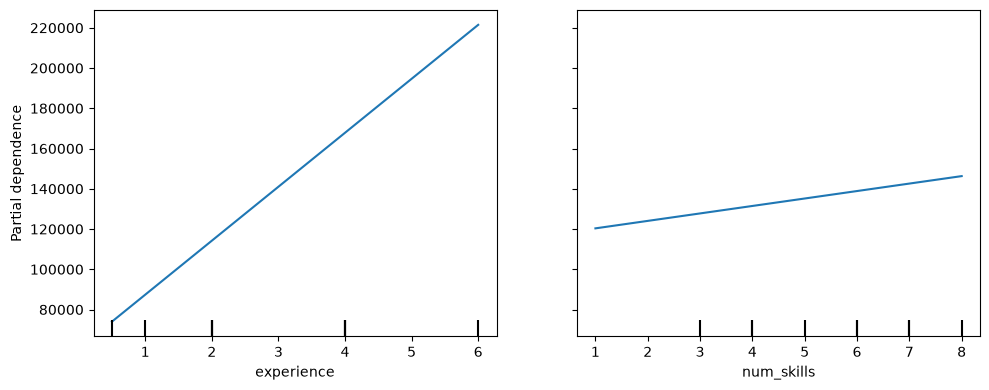

In [ ]:
from sklearn.inspection import PartialDependenceDisplay

continuous_features = [
    'experience',
    'num_skills'
]
X_test_pdp = X_test.copy()
X_test_pdp[continuous_features] = X_test_pdp[continuous_features].astype(float)
fig, ax = plt.subplots(figsize=(10, 4))
display = PartialDependenceDisplay.from_estimator(
    model,
    X_test_pdp,
    features=continuous_features,
    kind='average',
    grid_resolution=50,
    ax=ax
)
plt.tight_layout()
plt.show()

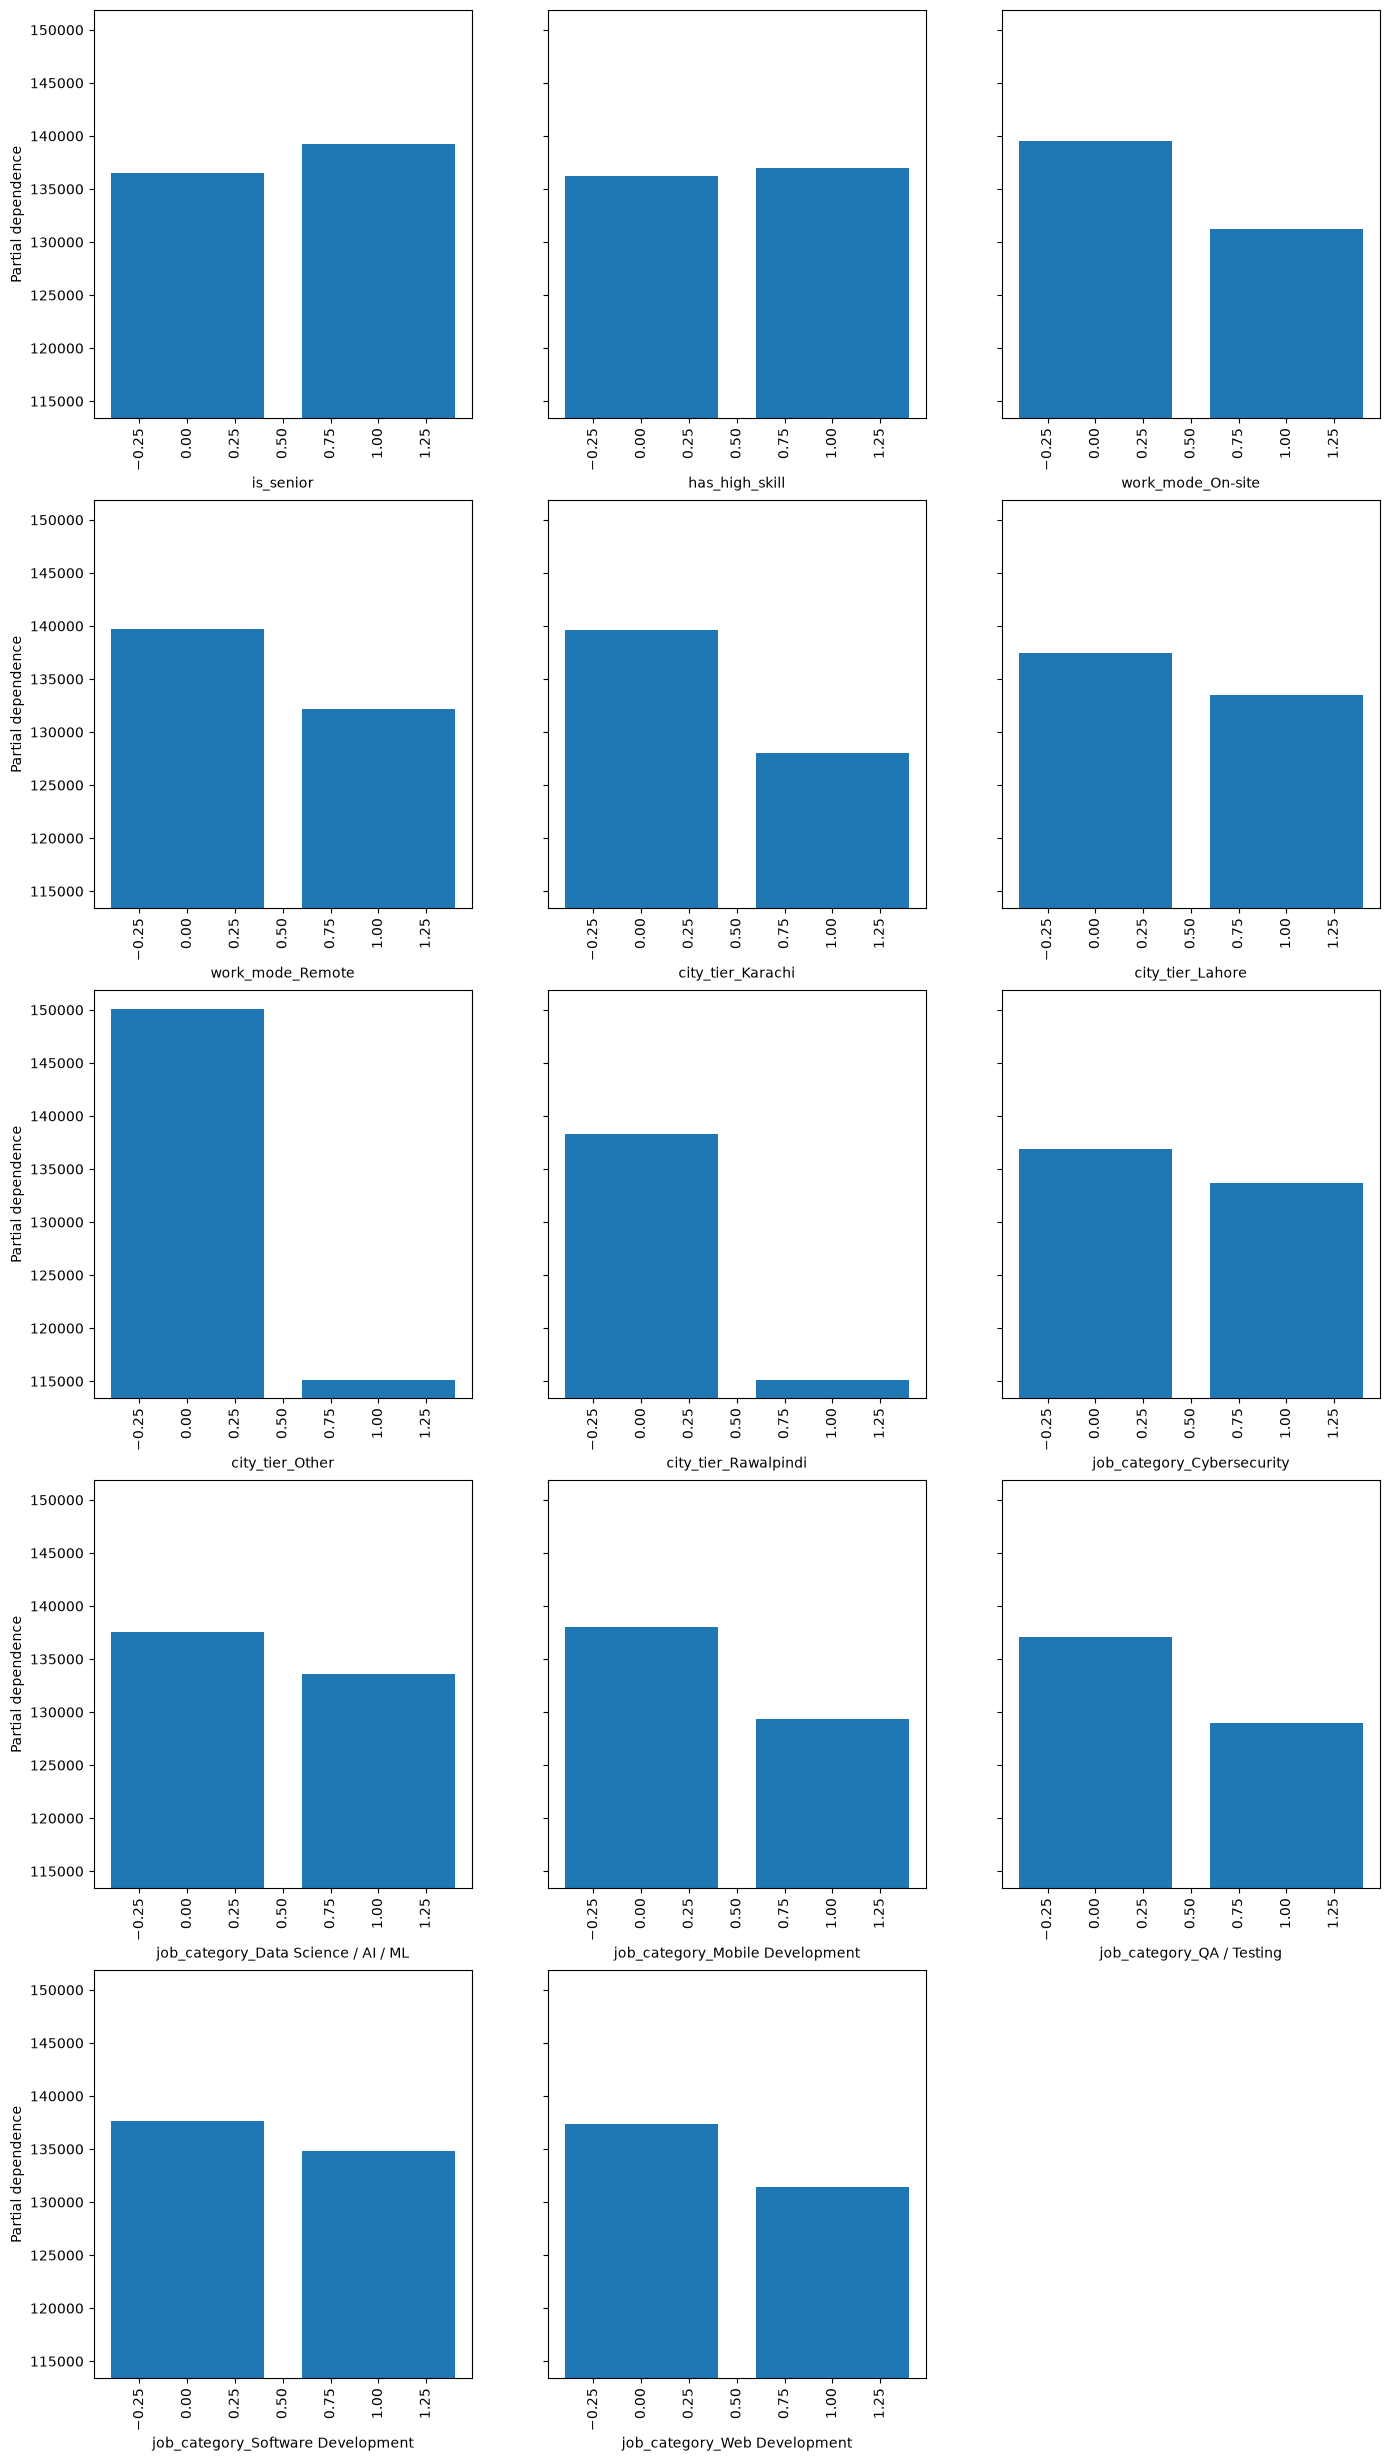

In [30]:
from sklearn.inspection import PartialDependenceDisplay
categorical_features = [
   i for i in X_test.columns if  i not in [
    'experience',
    'num_skills',
    'education'
]
]
fig, ax = plt.subplots(figsize=(14, len(categorical_features) * 1.75))
display=PartialDependenceDisplay.from_estimator(
    model,
    X_test,
    features=categorical_features,
    categorical_features=categorical_features,
    n_cols=3,
    ax=ax
)
plt.tight_layout()
plt.show()

Background dataset has 1575 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=1575 when initializing the masker.


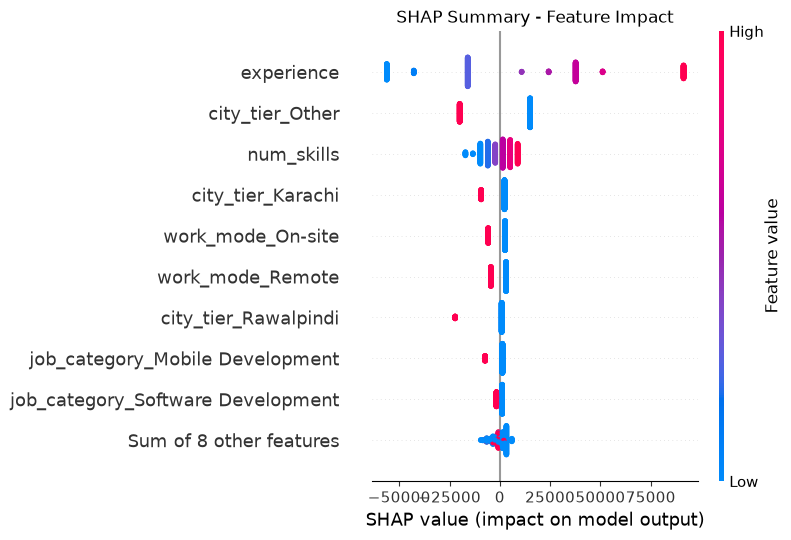

In [ ]:
import shap
explainer = shap.LinearExplainer(model,X_train)
plt.figure()
shap.plots.beeswarm(shap_values, show=False)
plt.title("SHAP Summary - Feature Impact")
plt.tight_layout()
plt.show()

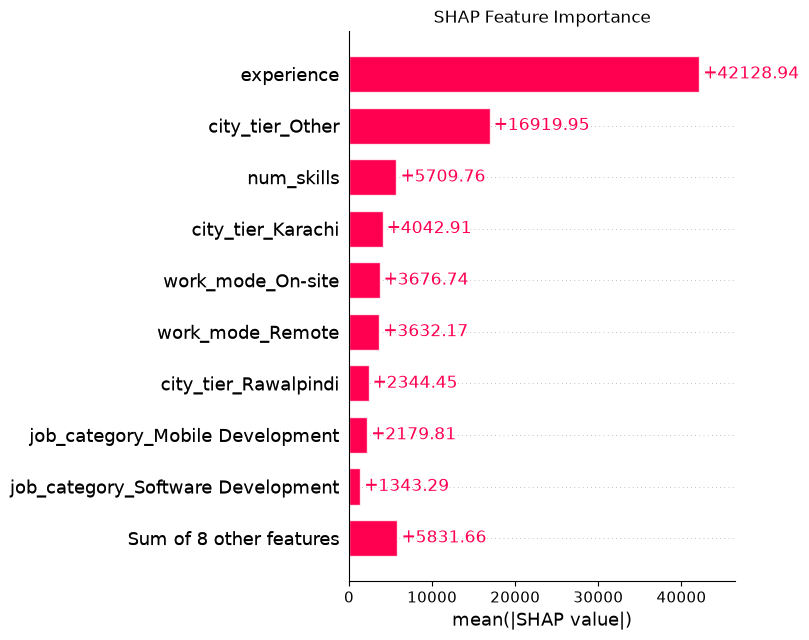

In [38]:
plt.figure()
shap.plots.bar(shap_values, show=False)
plt.title("SHAP Feature Importance")
plt.tight_layout()
plt.show()

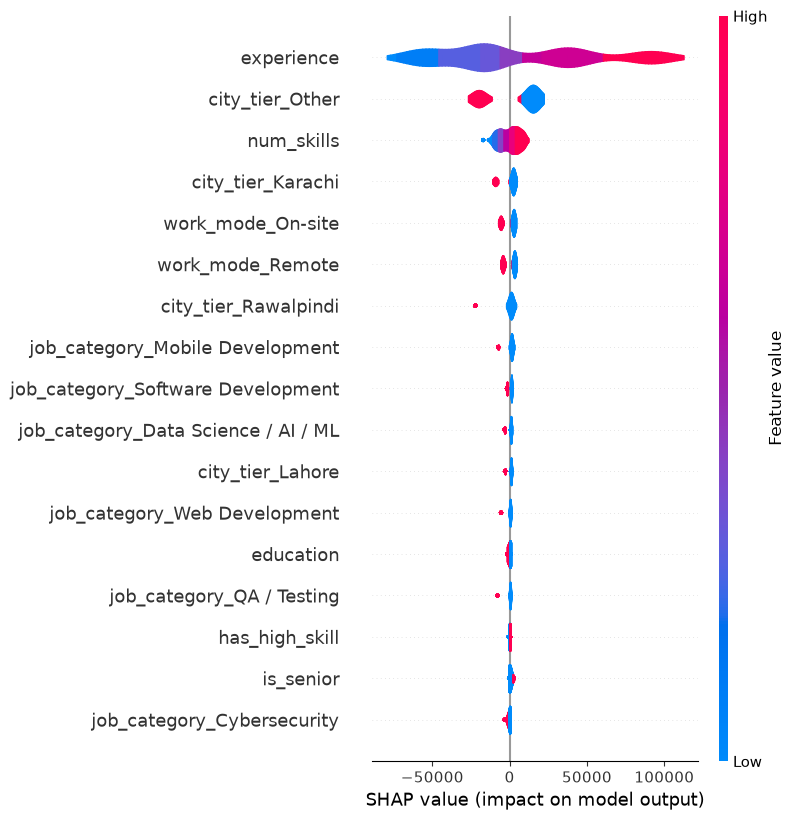

In [ ]:
shap.summary_plot(shap_values.values,X_test,plot_type='violin')